# Post pruning decision trees with cost complexity pruning: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/tree/plot_cost_complexity_pruning.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/tree/plot_cost_complexity_pruning.html)).

**Scenario:** `DecisionTreeClassifier(random_state=0).cost_complexity_pruning_path` on the bundled breast
cancer training split, then one classifier per effective alpha (`ccp_alpha`), comparing node counts,
`tree_.max_depth`, train/test accuracy, and every pruned tree's test predictions and
probabilities. An extra check compares `export_text` of a mid-path pruned tree.

**Adaptations:**
- Data comes from the bundled `load_breast_cancer` (no download). sklearn validates `X` to Float32
  inside `fit`/`predict`; Moxie trees take Float32 features, so the same Float32 matrix is shared.
- Labels are 0/1 integers: Moxie uses `DecisionTreeClassifier[DType.int64]` so `classes_` and
  predictions keep sklearn's integer dtype.
- `cost_complexity_pruning_path` returns a native `PruningPath` record with the same `ccp_alphas` and
  `impurities` fields instead of a `Bunch`.
- Moxie computes its own pruning path and fits on its own alphas; nothing fitted crosses from Python.
- The Python cells use the scikit-learn wheel installed in the notebooks environment; the tree code
  paths this example exercises are unchanged from the pinned revision (the family's oracle suites
  compare against a source build of the pinned revision).

**Determinism:** deterministic. `random_state=0` fixes the feature permutation and all features are
searched (`max_features=None`), so trees, alphas and scores must match.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("tree/plot_cost_complexity_pruning")

## 1. scikit-learn (Python reference)

The official example code, with smaller figures.

Number of nodes in the last tree is: 1 with ccp_alpha: 0.3272984419327777


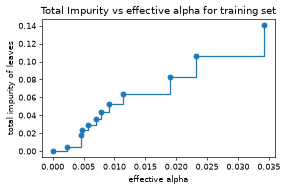

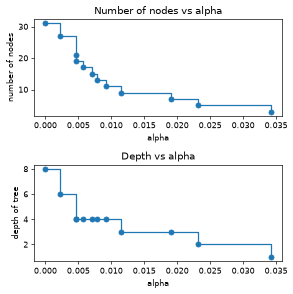

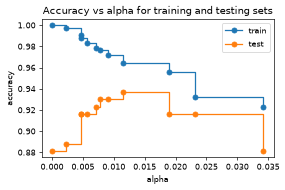

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text

plt.rcParams["figure.dpi"] = 60

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

clf = DecisionTreeClassifier(random_state=0)
path = clf.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(ccp_alphas[:-1], impurities[:-1], marker="o", drawstyle="steps-post")
ax.set_xlabel("effective alpha")
ax.set_ylabel("total impurity of leaves")
ax.set_title("Total Impurity vs effective alpha for training set")

clfs = []
for ccp_alpha in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=0, ccp_alpha=ccp_alpha)
    clf.fit(X_train, y_train)
    clfs.append(clf)
print(
    "Number of nodes in the last tree is: {} with ccp_alpha: {}".format(
        clfs[-1].tree_.node_count, ccp_alphas[-1]
    )
)
# Kept for parity: every tree's test predictions/probabilities and the last (root-only) tree.
sk_last_nodes = clfs[-1].tree_.node_count
sk_pred = np.stack([c.predict(X_test) for c in clfs])
sk_proba = np.stack([c.predict_proba(X_test) for c in clfs])
sk_text = export_text(clfs[len(clfs) // 2], show_weights=True)

clfs = clfs[:-1]
ccp_alphas = ccp_alphas[:-1]
node_counts = [clf.tree_.node_count for clf in clfs]
depth = [clf.tree_.max_depth for clf in clfs]
fig, ax = plt.subplots(2, 1, figsize=(5, 5))
ax[0].plot(ccp_alphas, node_counts, marker="o", drawstyle="steps-post")
ax[0].set_xlabel("alpha")
ax[0].set_ylabel("number of nodes")
ax[0].set_title("Number of nodes vs alpha")
ax[1].plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
ax[1].set_xlabel("alpha")
ax[1].set_ylabel("depth of tree")
ax[1].set_title("Depth vs alpha")
fig.tight_layout()

train_scores = [clf.score(X_train, y_train) for clf in clfs]
test_scores = [clf.score(X_test, y_test) for clf in clfs]
fig, ax = plt.subplots(figsize=(5, 3))
ax.set_xlabel("alpha")
ax.set_ylabel("accuracy")
ax.set_title("Accuracy vs alpha for training and testing sets")
ax.plot(ccp_alphas, train_scores, marker="o", label="train", drawstyle="steps-post")
ax.plot(ccp_alphas, test_scores, marker="o", label="test", drawstyle="steps-post")
ax.legend()
plt.show()

nb.share(X_train=X_train.astype(np.float32), y_train=y_train,
         X_test=X_test.astype(np.float32), y_test=y_test)

## 2. Moxie (native Mojo)

The same steps through `moxie.tree`. The path, every pruned fit, scoring and prediction run in Mojo.

In [3]:
%%mojo pruning
import numojo as nm
from moxie.tree import DecisionTreeClassifier, export_text
from moxie_nb_io import load, save, save_ints, save_floats, save_strings


def main() raises:
    var X_train = load[DType.float32]("X_train")
    var y_train = load[DType.int64]("y_train")
    var X_test = load[DType.float32]("X_test")
    var y_test = load[DType.int64]("y_test")

    var clf = DecisionTreeClassifier[DType.int64](random_state=0)
    var path = clf.cost_complexity_pruning_path(X_train, y_train)
    save("ccp_alphas", path.ccp_alphas)
    save("impurities", path.impurities)

    var n = path.ccp_alphas.size
    var m = X_test.shape[0]
    var node_counts = List[Int]()
    var depths = List[Int]()
    var train_scores = List[Float64]()
    var test_scores = List[Float64]()
    var pred = nm.zeros[DType.int64](nm.Shape(n, m))
    var proba = nm.zeros[DType.float64](nm.Shape(n, m, 2))
    for k in range(n):
        var tree = DecisionTreeClassifier[DType.int64](random_state=0, ccp_alpha=path.ccp_alphas.item(k))
        _ = tree.fit(X_train, y_train)
        node_counts.append(tree.tree_.node_count)
        depths.append(tree.tree_.max_depth)
        train_scores.append(tree.score(X_train, y_train))
        test_scores.append(tree.score(X_test, y_test))
        var p = tree.predict(X_test)
        var q = tree.predict_proba(X_test)[0].copy()
        for i in range(m):
            pred.itemset([k, i], p.item(i))
            for c in range(q.shape[1]):
                proba.itemset([k, i, c], q.item(i, c))
        if k == n // 2:
            save_strings("text", [export_text(tree, show_weights=True)])
    print("Number of nodes in the last tree is:", node_counts[n - 1], "with ccp_alpha:", path.ccp_alphas.item(n - 1))
    save_ints("node_counts", node_counts)
    save_ints("depths", depths)
    save_floats("train_scores", train_scores)
    save_floats("test_scores", test_scores)
    save("pred", pred)
    save("proba", proba)

Number of nodes in the last tree is: 1 with ccp_alpha: 0.32729844193277774


## 3. Side by side and parity

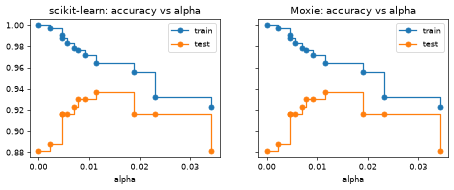

|--- feature_7 <= 0.05
|   |--- feature_23 <= 952.90
|   |   |--- weights: [7.00, 245.00] class: 1
|   |--- feature_23 >  952.90
|   |   |--- weights: [6.00, 2.00] class: 0
|--- feature_7 >  0.05
|   |--- feature_23 <= 785.80
|   |   |--- feature_21 <= 23.74
|   |   |   |--- weights: [0.00, 14.00] class: 1
|   |   |--- feature_21 >  23.74
|   |   |   |--- feature_25 <= 0.26
|   |   |   |   |--- weights: [0.00, 3.00] class: 1
|   |   |   |--- feature_25 >  0.26
|   |   |   |   |--- weights: [13.00, 0.00] class: 0
|   |--- feature_23 >  785.80
|   |   |--- feature_10 <= 0.19
|   |   |   |--- weights: [0.00, 2.00] class: 1
|   |   |--- feature_10 >  0.19
|   |   |   |--- weights: [133.00, 1.00] class: 0



In [4]:
mx = nb.results["pruning"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for ax, label, alphas, tr, te in [
        (axes[0], "scikit-learn", ccp_alphas, train_scores, test_scores),
        (axes[1], "Moxie", mx["ccp_alphas"][:-1], mx["train_scores"][:-1], mx["test_scores"][:-1])]:
    ax.plot(alphas, tr, marker="o", label="train", drawstyle="steps-post")
    ax.plot(alphas, te, marker="o", label="test", drawstyle="steps-post")
    ax.set_title(f"{label}: accuracy vs alpha")
    ax.set_xlabel("alpha")
    ax.legend()
plt.show()
moxie_nb.side_by_side(sklearn=np.c_[path.ccp_alphas, path.impurities],
                      moxie=np.c_[mx["ccp_alphas"], mx["impurities"]])

TOL = ("Float64 Gini sums and alpha differences; both sides accumulate weighted counts in the same order, "
       "2e-12 covers last-bit roundoff (the family oracle uses the same bound)")
nb.compare("ccp_alphas", path.ccp_alphas, mx["ccp_alphas"], rtol=2e-12, atol=2e-12, reason=TOL)
nb.compare("impurities", path.impurities, mx["impurities"], rtol=2e-12, atol=2e-12, reason=TOL)
nb.compare("node_count per alpha", node_counts + [sk_last_nodes], mx["node_counts"], exact=True)
nb.compare("tree_.max_depth per alpha", depth, mx["depths"][:-1], exact=True)
nb.compare("train accuracy per alpha", train_scores, mx["train_scores"][:-1], exact=True)
nb.compare("test accuracy per alpha", test_scores, mx["test_scores"][:-1], exact=True)
nb.compare("predict(X_test) for every alpha", sk_pred, mx["pred"], exact=True)
nb.compare("predict_proba(X_test) for every alpha", sk_proba, mx["proba"], rtol=1e-15, atol=1e-15,
           reason="leaf class fractions are one Float64 division of identical weighted counts")
nb.compare("export_text(show_weights=True), mid-path tree", np.array([sk_text]), mx["text"], exact=True)
print(sk_text)

In [5]:
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
ccp_alphas,PASS,"(13,)","(13,)",5.55e-17,1.7e-16,"rtol=2e-12, atol=2e-12",,"Float64 Gini sums and alpha differences; both sides accumulate weighted counts in the same order, 2e-12 covers last-bit roundoff (the family oracle uses the same bound)"
impurities,PASS,"(13,)","(13,)",2.78e-17,1.97e-16,"rtol=2e-12, atol=2e-12",,"Float64 Gini sums and alpha differences; both sides accumulate weighted counts in the same order, 2e-12 covers last-bit roundoff (the family oracle uses the same bound)"
node_count per alpha,PASS,"(13,)","(13,)",,,exact,0 mismatches,
tree_.max_depth per alpha,PASS,"(12,)","(12,)",,,exact,0 mismatches,
train accuracy per alpha,PASS,"(12,)","(12,)",,,exact,0 mismatches,
test accuracy per alpha,PASS,"(12,)","(12,)",,,exact,0 mismatches,
predict(X_test) for every alpha,PASS,"(13, 143)","(13, 143)",,,exact,0 mismatches,
predict_proba(X_test) for every alpha,PASS,"(13, 143, 2)","(13, 143, 2)",0,0,"rtol=1e-15, atol=1e-15",,leaf class fractions are one Float64 division of identical weighted counts
"export_text(show_weights=True), mid-path tree",PASS,"(1,)","(1,)",,,exact,0 mismatches,
